# Repeated Prisoners Dilemma

Five memory-based strategies play a round robin. A small action-error rate tests how a single accidental defection can change subsequent play.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Behavioural rules

A value of one means cooperation. Both players see the same realised history, including action errors.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

NAMES = ["Cooperate", "Defect", "Tit for tat", "Grim trigger", "Win-stay"]


def decide(rule, mine, theirs):
    if rule == 0:
        return 1
    if rule == 1:
        return 0
    if not mine:
        return 1
    if rule == 2:
        return theirs[-1]
    if rule == 3:
        return int(0 not in theirs)
    # Mutual cooperation and exploiting a cooperator are the two winning outcomes.
    return mine[-1] if theirs[-1] else 1 - mine[-1]


def match(i, j, rng, rounds=100):
    own = []
    opp = []
    rewards = []
    payoff = np.array([[1, 5], [0, 3]])
    for _ in range(rounds):
        a = decide(i, own, opp) ^ int(rng.random() < 0.02)
        b = decide(j, opp, own) ^ int(rng.random() < 0.02)
        own.append(a)
        opp.append(b)
        rewards.append(payoff[a, b])
    return np.mean(rewards), np.mean(own)

## Tournament payoff and cooperation

Every ordered pair plays sixty independent matches. The row strategy receives the displayed payoff.

Cooperate: mean payoff 1.800 | cooperation 98.1%
Defect: mean payoff 2.234 | cooperation 2.1%
Tit for tat: mean payoff 2.068 | cooperation 49.4%
Grim trigger: mean payoff 2.260 | cooperation 25.0%
Win-stay: mean payoff 2.164 | cooperation 64.6%
Largest pairwise Monte Carlo SE for mean payoff: 0.121


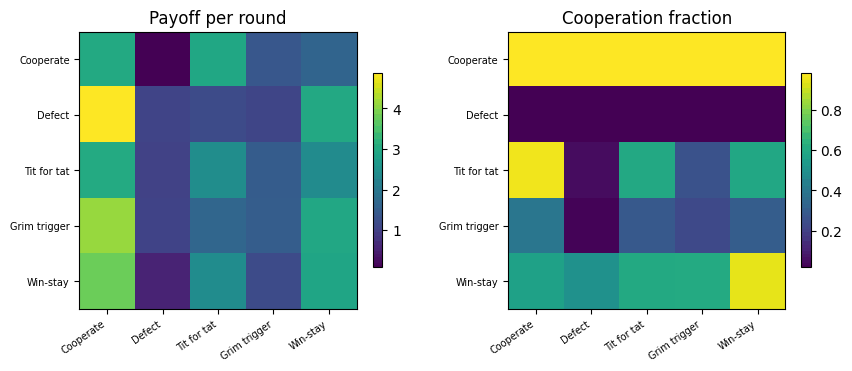

In [3]:
rng = np.random.default_rng(17)
score = np.zeros((5, 5))
coop = np.zeros((5, 5))
uncertainty = np.zeros((5, 5))
for i in range(5):
    for j in range(5):
        results = np.array([match(i, j, rng) for _ in range(60)])
        score[i, j], coop[i, j] = results.mean(0)
        uncertainty[i, j] = results[:, 0].std(ddof=1) / np.sqrt(len(results))
for name, reward, rate in zip(NAMES, score.mean(1), coop.mean(1)):
    print(f"{name}: mean payoff {reward:.3f} | cooperation {rate:.1%}")
print(f"Largest pairwise Monte Carlo SE for mean payoff: {uncertainty.max():.3f}")
fig, (a, b) = plt.subplots(1, 2, figsize=(8.7, 3.6), constrained_layout=True)
for ax, matrix, label in [(a, score, "Payoff per round"), (b, coop, "Cooperation fraction")]:
    im = ax.imshow(matrix, cmap="viridis")
    ax.set(title=label, xticks=range(5), yticks=range(5))
    ax.set_xticklabels(NAMES, rotation=35, ha="right", fontsize=7)
    ax.set_yticklabels(NAMES, fontsize=7)
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

## Reading the result

The opponent mix, error rate and horizon determine these tournament averages. A ranking here is conditional on those choices.

## References

[Axelrod and Hamilton, The Evolution of Cooperation (1981)](https://doi.org/10.1126/science.7466396)